#**DATA VISUALIZATION - LOG TRANSAKSI VENDING MACHINE ANTAR GEDUNG**

##**1. Import Library**

Library yang dibutuhkan untuk proses data visualization ini antara lain :

1. pandas (pd), digunakan untuk membaca file Excel, mengolah data dalam bentuk DataFrame, membersihkan data, melakukan filtering, dan menyimpan kembali dataset bersih.
2. numpy (np), untuk melakukan perhitungan matematika dan pengolahan angka/array dengan cepat.
3. matplotlib.pyplot (plt) untuk membuat dan mengatur tampilan dasar grafik (seperti ukuran, judul, dan label).
4. seaborn (sns) sebagai library visualisasi tingkat lanjut berbasis Matplotlib untuk membuat grafik lebih rapi dan menarik.




In [30]:
# Mengimpor library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##**2. Unggah Dataset dari Google Drive**

Selanjutnya dataset log transaksi VM diupload melalui google drive dan dihubungkan ke Colab, hingga pada akhirnya untuk mengecek keberhasilan pemanggilan data akan ditampilkan 10 data awal seperti hasil dibwah ini

In [32]:
# Menghubungkan Google Colab dengan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Membaca dataset dari Google Drive
file_path = '/content/drive/My Drive/2418014_DATASET VISUALIZATION/dataset_bersih_vending_machine.xlsx'
df = pd.read_excel(file_path)

# Menampilkan 10 baris pertama dataset untuk memastikan data berhasil dimuat
print("Jumlah baris dan kolom :", df.shape)
display(df.head(10))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah baris dan kolom : (300, 12)


,ID_Transaksi,Waktu_Transaksi,ID_Mesin,Nama_Produk,Kategori,Jumlah_Beli,Metode_Bayar,Total_Harga,Uang_Masuk,Status_Transaksi,Harga_Satuan,Hari
0,TRX-VM-001,2026-09-01 08:10:12,VM-GEDUNG_A-L1,Coca Cola 330 ml,Minuman,1,QRIS,8000,8000,SUCCESS,8000,Selasa
1,TRX-VM-002,2026-09-02 08:15:00,VM-GEDUNG_A-L1,Good Day Mocacinno,Minuman,1,QRIS,7000,7000,SUCCESS,7000,Rabu
2,TRX-VM-003,2026-09-02 08:20:00,VM-GEDUNG_B-L2,Pokka Green Tea 450ml,Minuman,2,CASH,16000,16000,SUCCESS,8000,Rabu
3,TRX-VM-004,2026-09-03 08:30:00,VM-GEDUNG_C-L3,Nescafe Latte,Kopi,1,SHOPEEPAY,12000,12000,FAILED,12000,Kamis
4,TRX-VM-005,2026-09-04 08:35:00,VM-GEDUNG_A-L1,Aqua 600 ml,Minuman,2,QRIS,4000,4000,SUCCESS,2000,Jumat
5,TRX-VM-006,2026-09-04 08:40:10,VM-GEDUNG_B-L2,Silverqueen 62g,Cokelat,1,E-MONEY,15000,0,PENDING,15000,Jumat
6,TRX-VM-007,2026-09-05 08:45:00,VM-GEDUNG_A-L1,Ultra Milk Cokelat,Minuman,1,FLAZZ,6000,6000,SUCCESS,6000,Sabtu
7,TRX-VM-008,2026-09-06 08:55:00,VM-GEDUNG_B-L2,Oreo Original 133g,Makanan Ringan,1,CASH,8000,10000,FAILED,8000,Minggu
8,TRX-VM-009,2026-09-07 09:05:00,VM-GEDUNG_C-L3,Pocari Sweat 500ml,Minuman,1,QRIS,9000,9000,SUCCESS,9000,Senin
9,TRX-VM-010,2026-09-08 09:20:00,VM-GEDUNG_A-L1,Teh Pucuk Harum,Minuman,2,FLAZZ,8000,10000,REFUND,4000,Selasa


##**3. Tahap Awal Pengolahan Data**

Sebelum melakukan visualisasi data, disini saya melakukan pengecekan ulang terhadap data yang ada untuk memastikan waktu transaksi sudah sesuai tipenya (datetime) dan juga nilai yang ada tidak kosong (missing values). Dari hasilnya, didapat bahwa saat ini kolom sudah bersih dari missing values!

In [33]:
# Mengecek informasi struktur kolom dan tipe data
df.info()

# Memastikan kolom Waktu_Transaksi dikonversi ke tipe datetime
df['Waktu_Transaksi'] = pd.to_datetime(df['Waktu_Transaksi'])

# Mengecek apa ada nilai yang kosong (missing values)
print("\nJumlah Missing Value per Kolom :")
print(df.isnull().sum())

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ID_Transaksi      300 non-null    object        
 1   Waktu_Transaksi   300 non-null    datetime64[ns]
 2   ID_Mesin          300 non-null    object        
 3   Nama_Produk       300 non-null    object        
 4   Kategori          300 non-null    object        
 5   Jumlah_Beli       300 non-null    int64         
 6   Metode_Bayar      300 non-null    object        
 7   Total_Harga       300 non-null    int64         
 8   Uang_Masuk        300 non-null    int64         
 9   Status_Transaksi  300 non-null    object        
 10  Harga_Satuan      300 non-null    int64         
 11  Hari              300 non-null    object        
dtypes: datetime64[ns](1), int64(4), object(7)
memory usage: 28.3+ KB

Jumlah Missing Value per Kolom :
ID_Transaksi        0
Waktu_Transak

,Waktu_Transaksi,Jumlah_Beli,Total_Harga,Uang_Masuk,Harga_Satuan
count,300,300.000000,300.000000,300.000000,300.000000
mean,2026-10-03 03:38:55.586666752,1.243333,10196.666667,9073.333333,8245.000000
min,2026-09-01 08:10:12,1.000000,2000.000000,0.000000,2000.000000
25%,2026-09-28 00:08:48.249999872,1.000000,7000.000000,6000.000000,6000.000000
50%,2026-10-04 05:59:17.500000,1.000000,9000.000000,8000.000000,8000.000000
75%,2026-10-10 08:47:10.249999872,1.000000,12000.000000,12000.000000,10000.000000
max,2026-10-16 06:34:48,3.000000,45000.000000,45000.000000,15000.000000
std,NaN,0.533922,5864.380509,6187.128366,3030.912365


##**4. Ekstraksi Waktu Transaksi**

Untuk mempermudah visualisasi tren data, saya menambahkan kolom baru berupa bulan dan tanggal harian yang diekstrak langsung dari kolom waktu transaksi.

In [34]:
# Membuat kolom Bulan (YYYY-MM) untuk analisis tren bulanan
df['Bulan'] = df['Waktu_Transaksi'].dt.to_period('M')

# Membuat kolom Tanggal harian
df['Tanggal'] = df['Waktu_Transaksi'].dt.date

print("Hasil pengolahan data waktu :")
df[['Waktu_Transaksi', 'Bulan', 'Tanggal']].head()

Hasil pengolahan data waktu :


,Waktu_Transaksi,Bulan,Tanggal
0,2026-09-01 08:10:12,2026-09,2026-09-01
1,2026-09-02 08:15:00,2026-09,2026-09-02
2,2026-09-02 08:20:00,2026-09,2026-09-02
3,2026-09-03 08:30:00,2026-09,2026-09-03
4,2026-09-04 08:35:00,2026-09,2026-09-04


##**5. Visualisasi 1 - Tren Pendapatan Penjualan**

Pada visualisasi pertama ini, data dikategorikan berdasarkan tanggal untuk menemukan jumlah total pendapatan yang kemudian ditampilkan dalam bentuk grafik garis dengan label dalam Rupiah sehingga kenaikan dan penurunan dalam tren penjualan terlihat jelas. Terakhir, data 3 pendapatan harian tertinggi akan secara otomatis diurutkan dan ditampilkan.

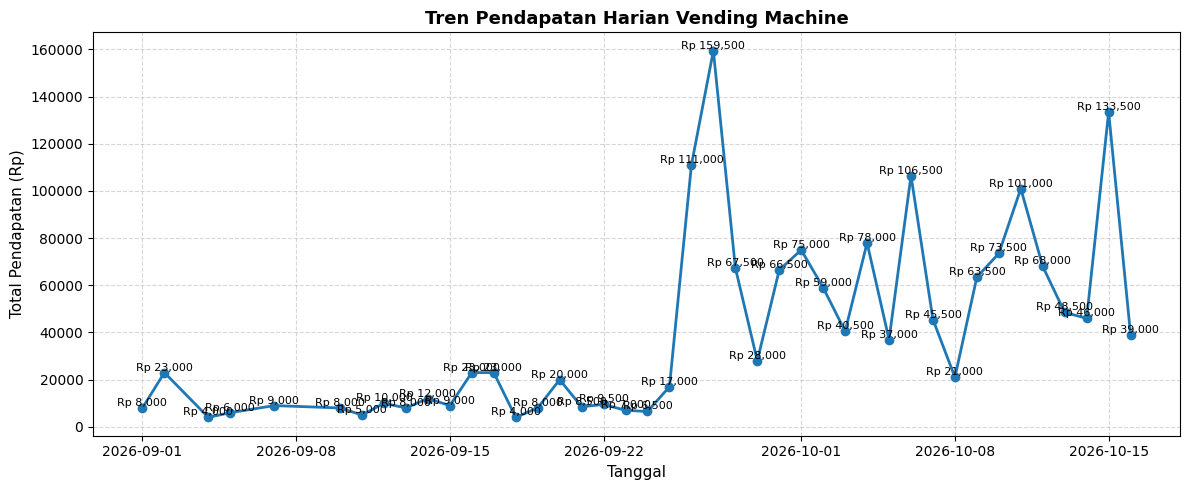


TOP 3 PENDAPATAN HARIAN TERTINGGI :
1. 2026-09-27 — Rp 159,500
2. 2026-10-15 — Rp 133,500
3. 2026-09-26 — Rp 111,000


In [35]:
# 1. Hitung total pendapatan harian (khusus status SUCCESS)
daily_rev = df[df['Status_Transaksi'] == 'SUCCESS'].groupby('Tanggal')['Total_Harga'].sum().reset_index()
daily_rev['Tanggal_DT'] = pd.to_datetime(daily_rev['Tanggal'])

# 2. Buat line chart pendapatan harian
plt.figure(figsize=(12, 5))
plt.plot(daily_rev['Tanggal_DT'], daily_rev['Total_Harga'], marker='o', color='#1f77b4', linewidth=2)

# Tambahkan label angka di setiap titik grafik
for _, row in daily_rev.iterrows():
    plt.text(row['Tanggal_DT'], row['Total_Harga'], f"Rp {row['Total_Harga']:,.0f}",
             ha='center', va='bottom', fontsize=8)

plt.title('Tren Pendapatan Harian Vending Machine', fontsize=13, fontweight='bold')
plt.xlabel('Tanggal', fontsize=11)
plt.ylabel('Total Pendapatan (Rp)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Menampilkan Top 3 pendapatan harian tertinggi
print("\nTOP 3 PENDAPATAN HARIAN TERTINGGI :")
top3 = daily_rev.sort_values(by='Total_Harga', ascending=False).head(3)
for i, (_, row) in enumerate(top3.iterrows(), 1):
    print(f"{i}. {row['Tanggal']} — Rp {row['Total_Harga']:,.0f}")

##**6. Visualisasi 2 - Produk Terlaris Berdasarkan Jumlah Pembelian**

Selanjutnya, pada visualisasi kedua yaitu berfokus pada jumlah pembelian terbanyak berdasarkan data produk yang ada. Data didapatkan dari variabel nama_produk dan jumlah_beli yang dihitung dan kemudian divisualisasikan kedalam grafik batang dengan menampilkan 10 produk makanan maupun minuman beserta total unit yang terjual dan paling laris dicari.

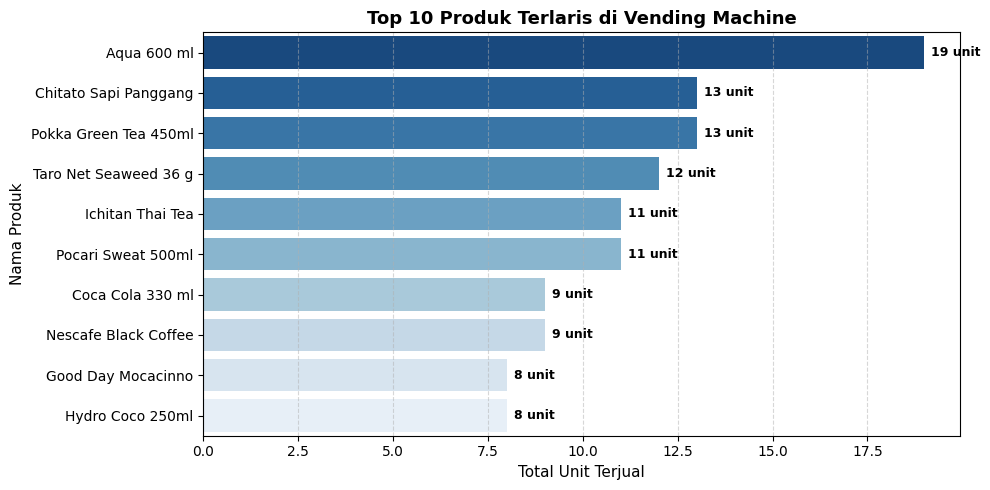

In [36]:
# 1. Hitung 10 produk terlaris khusus transaksi SUCCESS
top_products = (
    df[df['Status_Transaksi'] == 'SUCCESS']
    .groupby('Nama_Produk')['Jumlah_Beli']
    .sum()
    .nlargest(10)
    .reset_index()
)

# 2. Buat visualisasi bar chart
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=top_products, x='Jumlah_Beli', y='Nama_Produk',
                 hue='Nama_Produk', palette='Blues_r', legend=False)
plt.title('Top 10 Produk Terlaris di Vending Machine', fontsize=13, fontweight='bold')
plt.xlabel('Total Unit Terjual', fontsize=11)
plt.ylabel('Nama Produk', fontsize=11)

# Menampilkan angka di ujung batang grafik
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width)} unit', (width, p.get_y() + p.get_height() / 2),
                xytext=(5, 0), textcoords='offset points', va='center', fontsize=9, fontweight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##**7. Visualisasi 3 - Distribusi Metode Pembayaran**

Selain itu, di visualisasi ketiga untuk mengetahui metode pembayaran mana yang saat ini banyak digunakan oleh pembeli, disini saya juga melakukan pemvisualisasian data melalui grafik pie. Dari hasil yang didapat, penggunaan QRIS masih unggul dengan persentase yaitu 32.7%.

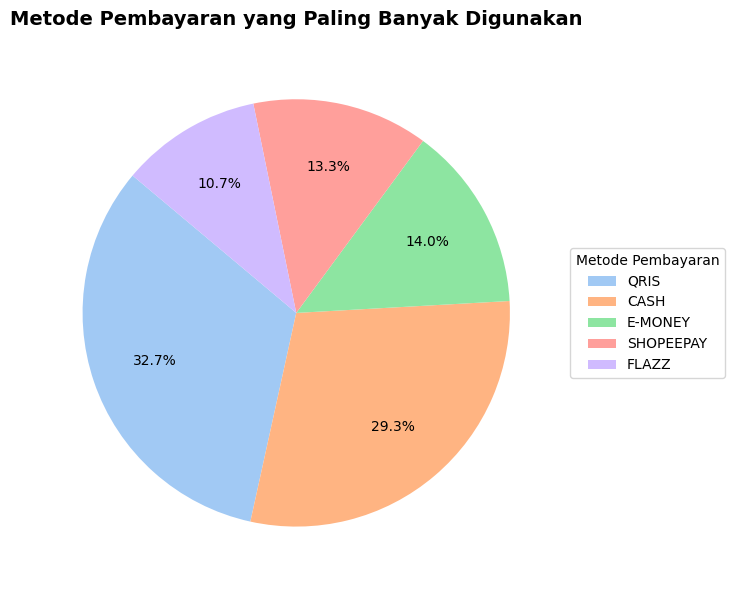

In [37]:
# Menghitung frekuensi penggunaan metode pembayaran
payment_counts = df['Metode_Bayar'].value_counts()
# Membuat visualisasi pie chart
plt.figure(figsize=(9, 6))

plt.pie(payment_counts,
        labels=None,
        autopct='%1.1f%%',
        startangle=140,
        colors=sns.color_palette('pastel'),
        pctdistance=0.7)

# Menampilkan nama metode pembayaran di samping grafik
plt.legend(payment_counts.index,
           title='Metode Pembayaran',
           loc='center left',
           bbox_to_anchor=(1, 0.5))
plt.title('Metode Pembayaran yang Paling Banyak Digunakan',
          fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

##**8. Visualisasi 4 - Jumlah Transaksi Berdasarkan Jam**

Pada visualisasi yang keempat, saya menggunakan line chart agar bisa melihat pola kebiasaan waktu kunjungan konsumen dari jam ke jam dengan jelas. Bagian paling penting yang dicari mahasiswa dari grafik ini adalah titik puncak tertinggi pada garis, yaitu di jam sekitar 08.00 hingga 10.00 WIB.

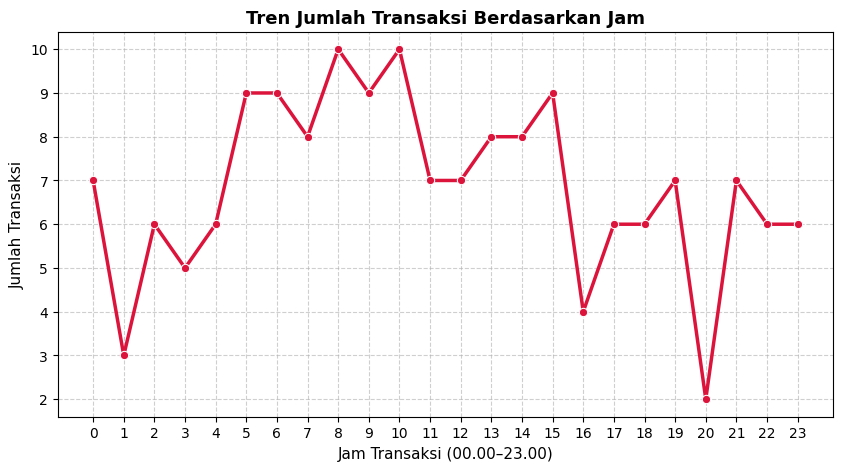

In [39]:
success_df = df[df['Status_Transaksi'] == 'SUCCESS'].copy()
# Mengambil jam transaksi
success_df['Jam'] = success_df['Waktu_Transaksi'].dt.hour

# Menghitung jumlah transaksi setiap jam
hourly_trend = success_df.groupby('Jam')['ID_Transaksi'].count().reset_index()
plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_trend, x='Jam', y='ID_Transaksi',
             marker='o', color='crimson', linewidth=2.5)
plt.title('Tren Jumlah Transaksi Berdasarkan Jam',
          fontsize=13, fontweight='bold')
plt.xlabel('Jam Transaksi (00.00–23.00)', fontsize=11)
plt.ylabel('Jumlah Transaksi', fontsize=11)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

##**9. Visualisasi 5 - Distribusi Status Transaksi**

Selanjutnya, disini saya juga menganalisis data distribusi status transaksi menggunakan bar chart. Pemilihan grafik bertujuan untuk memantau kesehatan operasional vending machine. Dari hasil yang didapatkan, status transaksi SUCCESS masih mendominasi yang berarti sistem Vending Machine secara keseluruhan berjalan dengan baik.

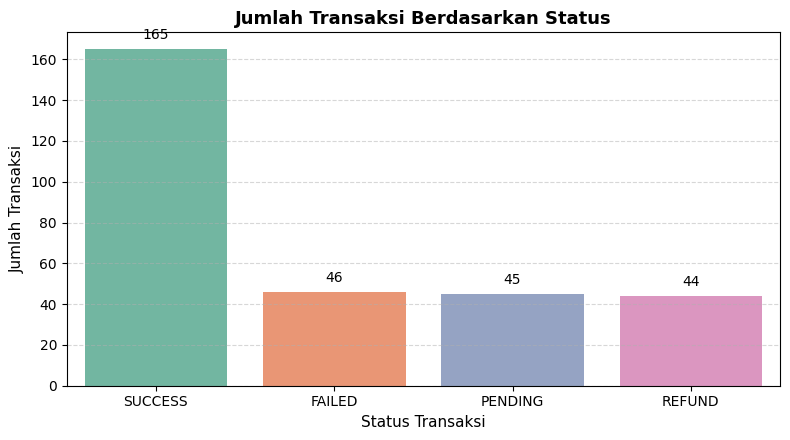

In [40]:
# Visualisasi jumlah transaksi berdasarkan status
plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=df, x='Status_Transaksi',
                   order=df['Status_Transaksi'].value_counts().index,
                   hue='Status_Transaksi', palette='Set2', legend=False)

# Menampilkan angka di atas setiap batang grafik
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontsize=10)

plt.title('Jumlah Transaksi Berdasarkan Status', fontsize=13, fontweight='bold')
plt.xlabel('Status Transaksi', fontsize=11)
plt.ylabel('Jumlah Transaksi', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##**10. Visualisasi 6 - Total Pendapatan Berdasarkan ID Mesin**

Terakhir, pada visualisasi keenam digunakan untuk mengetahui total pendapatan keseluruhan dari bulan September hingga pertengahan Oktober 2026 dari tiap vending machine baik itu VM-GEDUNG_A-L1, VM-GEDUNG_A-L2, dan VM-GEDUNG_A-L3. Dari ketiganya, pendapatan VM-GEDUNG_A-L1 paling tinggi yaitu Rp. 635.000.

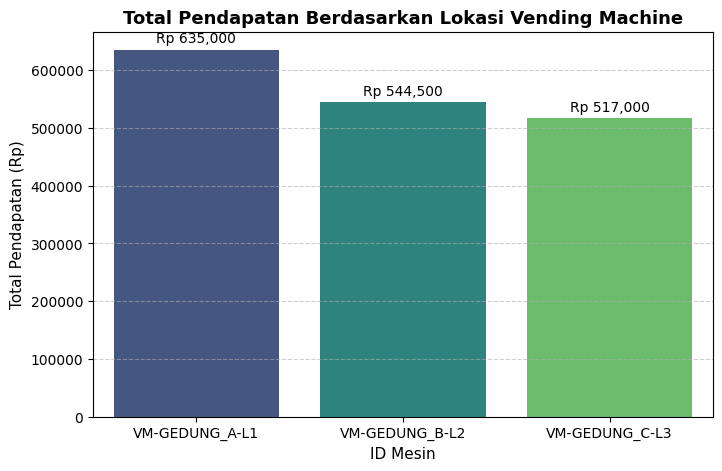

In [41]:
# Pendapatan berdasarkan Mesin
machine_rev = success_df.groupby('ID_Mesin')['Total_Harga'].sum().reset_index()

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=machine_rev, x='ID_Mesin', y='Total_Harga', hue='ID_Mesin', palette='viridis', legend=False)
plt.title('Total Pendapatan Berdasarkan Lokasi Vending Machine', fontsize=13, fontweight='bold')
plt.xlabel('ID Mesin', fontsize=11)
plt.ylabel('Total Pendapatan (Rp)', fontsize=11)

# Menampilkan angka total pendapatan di atas setiap batang grafik
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'Rp {height:,.0f}', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

##**11. Kesimpulan**

Melalui proses visualisasi data ini, data mentah vending machine dapat diolah, diorganisir dan dibersihkan melalui proses penyaringan dan ekstraksi waktu. Lewat berbagai grafik yang dibuat, kita bisa langsung melihat informasi penting seperti tren pendapatan selama beberapa hari,data produk terlaris, metode pembayaran yang paling sering dipakai, waktu sibuk bagi konsumen, total pendapatan berdasarkan ID Mesin, keberhasilan kinerja VM, hingga kondisi kesehatan mesin. Hal ini sangat berguna dalam mengevaluasi kinerja penjualan mesin dan bisa dijadikan bahan pengambilan keputusan bisnis yang akurat dan cepat.